# Book Recommender System using a Medallion Data Lake

**Data Mining Lab Assignment**

Dataset: Book-Crossing (Users, Books, Book-Ratings)

Flow: **Bronze** (raw copy) → **Silver** (clean data) → **Gold** (model-ready data) → **Item-based collaborative filtering**

Run all cells from top to bottom. The notebook downloads the data by itself.

## Step 1: Set up the data lake and build the Bronze layer

In [1]:
import csv
import html
import re
import urllib.request
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_colwidth", 80)

RAW, BRONZE, SILVER, GOLD = Path("raw"), Path("bronze"), Path("silver"), Path("gold")
for folder in (RAW, BRONZE, SILVER, GOLD):
    folder.mkdir(exist_ok=True)

In [2]:
DATA_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
zip_path = RAW / "book-crossings.zip"

if not zip_path.exists():
    request = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request) as response:
        zip_path.write_bytes(response.read())

with zipfile.ZipFile(zip_path) as archive:
    archive.extractall(RAW)

sorted((p.name, p.stat().st_size) for p in RAW.rglob("*.csv"))

[('BX-Book-Ratings.csv', 30682276),
 ('BX-Books.csv', 77787439),
 ('BX-Users.csv', 12284157)]

The files use `;` as the separator and are **not UTF-8**, so they are read with `latin-1`.
Quotes inside a title are written as `\\"`, so `escapechar` is set too.
All columns are read as text and nothing is converted, so Bronze stays the same as the source.

In [3]:
def read_raw(file_name):
    path = next(RAW.rglob(file_name))
    return pd.read_csv(
        path,
        sep=";",
        encoding="latin-1",
        quotechar='"',
        escapechar="\\",
        quoting=csv.QUOTE_MINIMAL,
        dtype=str,
        keep_default_na=False,   # keep "NULL" and empty text exactly as written
        on_bad_lines="warn",     # report any broken line instead of hiding it
    )


raw_tables = {
    "users": read_raw("BX-Users.csv"),
    "books": read_raw("BX-Books.csv"),
    "ratings": read_raw("BX-Book-Ratings.csv"),
}

ingested_at = datetime.now(timezone.utc)
for name, table in raw_tables.items():
    table["ingestion_timestamp"] = ingested_at
    table.to_parquet(BRONZE / f"{name}.parquet", index=False)
    print(f"bronze/{name}.parquet saved: {table.shape}")

bronze/users.parquet saved: (278858, 4)


bronze/books.parquet saved: (271379, 9)
bronze/ratings.parquet saved: (1149780, 4)


## Step 2: Explore the Bronze data (EDA)

In [4]:
users_b = pd.read_parquet(BRONZE / "users.parquet")
books_b = pd.read_parquet(BRONZE / "books.parquet")
ratings_b = pd.read_parquet(BRONZE / "ratings.parquet")
bronze = {"users": users_b, "books": books_b, "ratings": ratings_b}

MISSING_WORDS = {"", "null", "n/a", "nan"}


def missing_count(column):
    if column.name == "ingestion_timestamp":
        return int(column.isna().sum())
    return int((column.isna() | column.astype(str).str.strip().str.lower().isin(MISSING_WORDS)).sum())


for name, table in bronze.items():
    print(f"\n===== {name}: {table.shape[0]:,} rows, {table.shape[1]} columns =====")
    display(pd.DataFrame({
        "dtype": table.dtypes.astype(str),
        "missing": [missing_count(table[c]) for c in table.columns],
    }))
    display(table.head(3))


===== users: 278,858 rows, 4 columns =====


,dtype,missing
User-ID,str,0
Location,str,0
Age,str,110762
ingestion_timestamp,"datetime64[us, UTC]",0


,User-ID,Location,Age,ingestion_timestamp
0,1,"nyc, new york, usa",NULL,2026-11-27 08:03:32.046433+00:00
1,2,"stockton, california, usa",18,2026-11-27 08:03:32.046433+00:00
2,3,"moscow, yukon territory, russia",NULL,2026-11-27 08:03:32.046433+00:00



===== books: 271,379 rows, 9 columns =====


,dtype,missing
ISBN,str,0
Book-Title,str,0
Book-Author,str,1
Year-Of-Publication,str,0
Publisher,str,2
Image-URL-S,str,0
Image-URL-M,str,0
Image-URL-L,str,0
ingestion_timestamp,"datetime64[us, UTC]",0


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0195153448.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0195153448.01.LZZZZZZZ.jpg,2026-11-27 08:03:32.046433+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0002005018.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0002005018.01.LZZZZZZZ.jpg,2026-11-27 08:03:32.046433+00:00
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0060973129.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0060973129.01.LZZZZZZZ.jpg,2026-11-27 08:03:32.046433+00:00



===== ratings: 1,149,780 rows, 4 columns =====


,dtype,missing
User-ID,str,0
ISBN,str,0
Book-Rating,str,0
ingestion_timestamp,"datetime64[us, UTC]",0


,User-ID,ISBN,Book-Rating,ingestion_timestamp
0,276725,034545104X,0,2026-11-27 08:03:32.046433+00:00
1,276726,0155061224,5,2026-11-27 08:03:32.046433+00:00
2,276727,0446520802,0,2026-11-27 08:03:32.046433+00:00


In [5]:
print("Exact duplicate rows:")
for name, table in bronze.items():
    print(f"  {name}: {table.drop(columns='ingestion_timestamp').duplicated().sum():,}")

print("Duplicate keys after trimming and upper-casing:")
print("  users (User-ID):", users_b["User-ID"].str.strip().duplicated().sum())
print("  books (ISBN):", books_b["ISBN"].str.strip().str.upper().duplicated().sum())
print("  ratings (User-ID, ISBN):", pd.DataFrame({
    "u": ratings_b["User-ID"].str.strip(),
    "i": ratings_b["ISBN"].str.strip().str.upper(),
}).duplicated().sum())

orphan_books = ~ratings_b["ISBN"].str.strip().str.upper().isin(books_b["ISBN"].str.strip().str.upper())
orphan_users = ~ratings_b["User-ID"].str.strip().isin(users_b["User-ID"].str.strip())
print(f"Ratings whose book is not in Books: {orphan_books.sum():,} ({orphan_books.mean():.1%})")
print(f"Ratings whose user is not in Users: {orphan_users.sum():,}")

Exact duplicate rows:


  users: 0


  books: 0


  ratings: 0
Duplicate keys after trimming and upper-casing:
  users (User-ID): 0
  books (ISBN): 315


  ratings (User-ID, ISBN): 0


Ratings whose book is not in Books: 118,602 (10.3%)
Ratings whose user is not in Users: 0


**Finding:** Users has 278,858 rows (Age missing in 110,762), Books 271,379 rows (1 author and 2 publishers missing), Ratings 1,149,780 rows (nothing missing), all source columns are text, 315 ISBNs repeat after upper-casing, and 10.3% of ratings point to unknown books → **Silver:** convert types, mark missing values, remove duplicates and unknown books.

### 2.2 Distribution of ratings

,count
Book-Rating,
0,716109
1,1770
2,2759
3,5996
4,8904
5,50974
6,36924
7,76457
8,103736


Ratings equal to 0: 716,109 (62.3%)


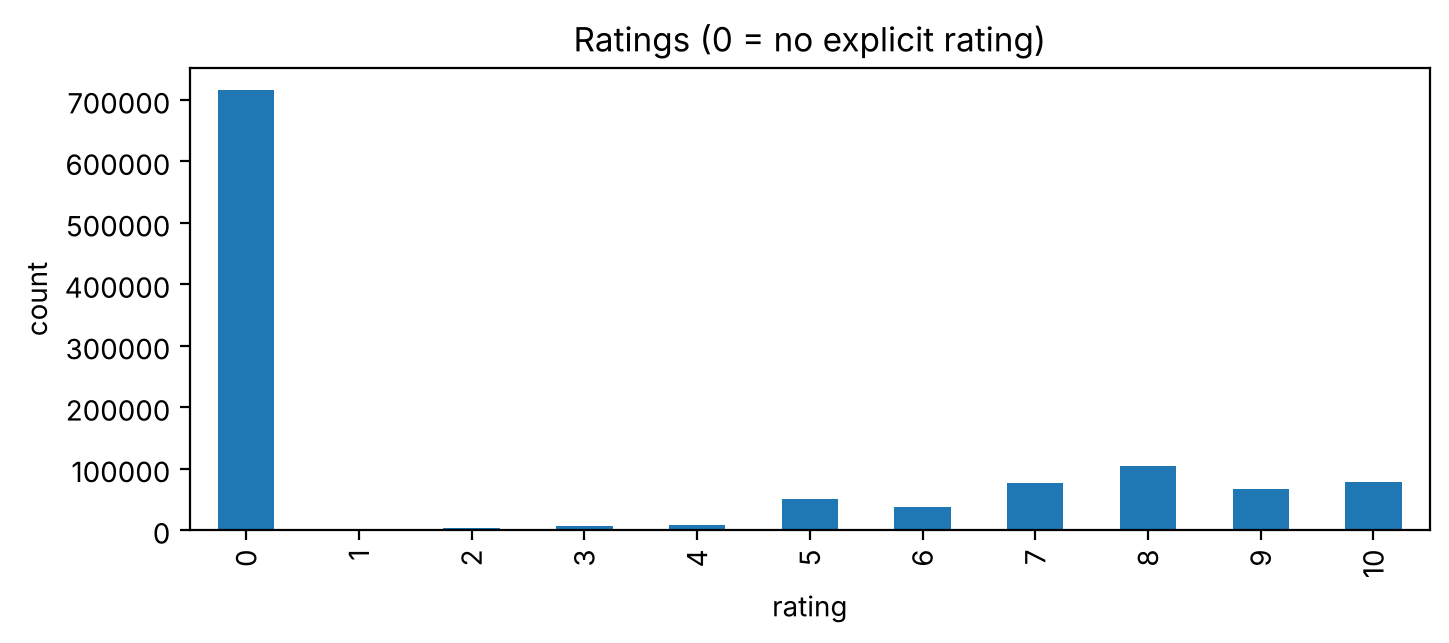

In [6]:
rating_values = pd.to_numeric(ratings_b["Book-Rating"], errors="coerce")
rating_counts = rating_values.value_counts().sort_index()
display(rating_counts.to_frame("count"))
print(f"Ratings equal to 0: {(rating_values == 0).sum():,} ({(rating_values == 0).mean():.1%})")

rating_counts.plot(kind="bar", figsize=(8, 3), title="Ratings (0 = no explicit rating)")
plt.xlabel("rating")
plt.ylabel("count")
plt.show()

**Finding:** 716,109 ratings (62.3%) are 0 and the most common real rating is 8 → **Silver:** remove all 0 ratings because they are not real scores, and keep 1 to 10.

### 2.3 User ages and publication years

,age,year
count,168096.000000,271379.000000
mean,34.751434,1959.756050
std,14.428097,258.011363
min,0.000000,0.000000
25%,24.000000,1989.000000
50%,32.000000,1995.000000
75%,44.000000,2000.000000
max,244.000000,2050.000000


Age missing: 110,762 (39.7%)
Age below 5: 882 | Age above 100: 366 | max age: 244.0
Year not a number: 0
Year = 0: 4,619 | Year in the future: 11 | Year after 2004 (dataset was collected in 2004): 72
Year between 1 and 1799: 2


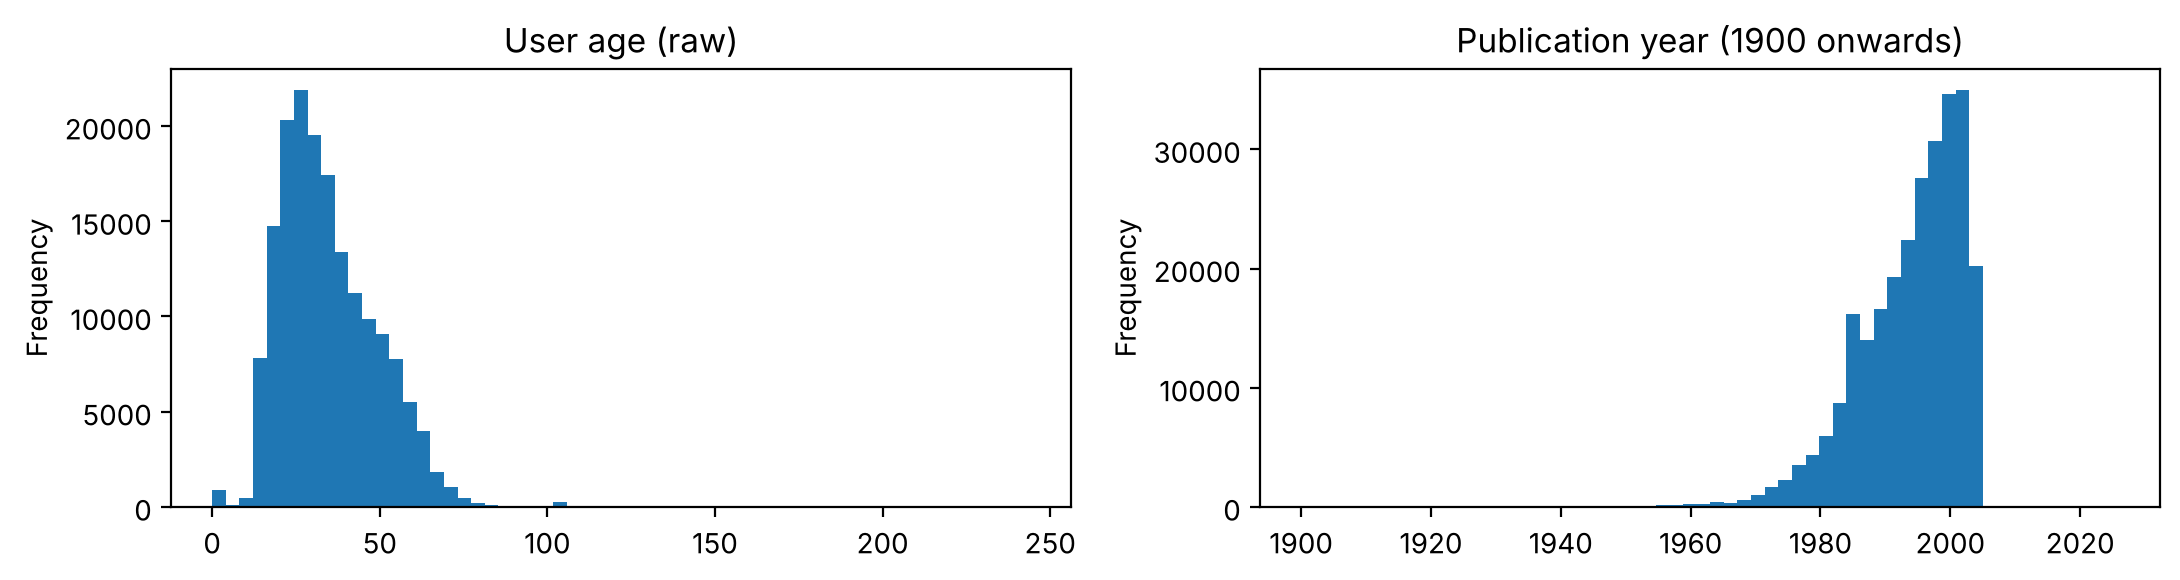

In [7]:
ages = pd.to_numeric(users_b["Age"], errors="coerce")
years = pd.to_numeric(books_b["Year-Of-Publication"], errors="coerce")
this_year = datetime.now().year

display(pd.DataFrame({"age": ages.describe(), "year": years.describe()}))
print(f"Age missing: {ages.isna().sum():,} ({ages.isna().mean():.1%})")
print(f"Age below 5: {(ages < 5).sum():,} | Age above 100: {(ages > 100).sum():,} | max age: {ages.max()}")
print(f"Year not a number: {years.isna().sum():,}")
print(f"Year = 0: {(years == 0).sum():,} | Year in the future: {(years > this_year).sum():,} | "
      f"Year after 2004 (dataset was collected in 2004): {(years > 2004).sum():,}")
print(f"Year between 1 and 1799: {years.between(1, 1799).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
ages.dropna().plot(kind="hist", bins=60, ax=axes[0], title="User age (raw)")
years[years.between(1900, this_year)].plot(kind="hist", bins=60, ax=axes[1], title="Publication year (1900 onwards)")
plt.tight_layout()
plt.show()

**Finding (age):** 39.7% of ages are missing, 882 are below 5 and 366 are above 100 (max 244) → **Silver:** set impossible ages to null, then fill all nulls with the median age.

**Finding (year):** 4,619 books have year 0 and 11 have a future year (up to 2050); a few others look doubtful (72 after 2004, 2 before 1800) → **Silver:** set 0 and future years to null, and keep the others because the task does not ask to remove them.

### 2.4 Number of ratings per user and per book

,ratings per user,ratings per book
count,105283.000000,340556.000000
mean,10.920851,3.376185
std,90.562825,12.436252
min,1.000000,1.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,4.000000,2.000000
max,13602.000000,2502.000000


users: 56.2% have only 1 rating, 87.6% have fewer than 10
books: 57.9% have only 1 rating, 94.6% have fewer than 10


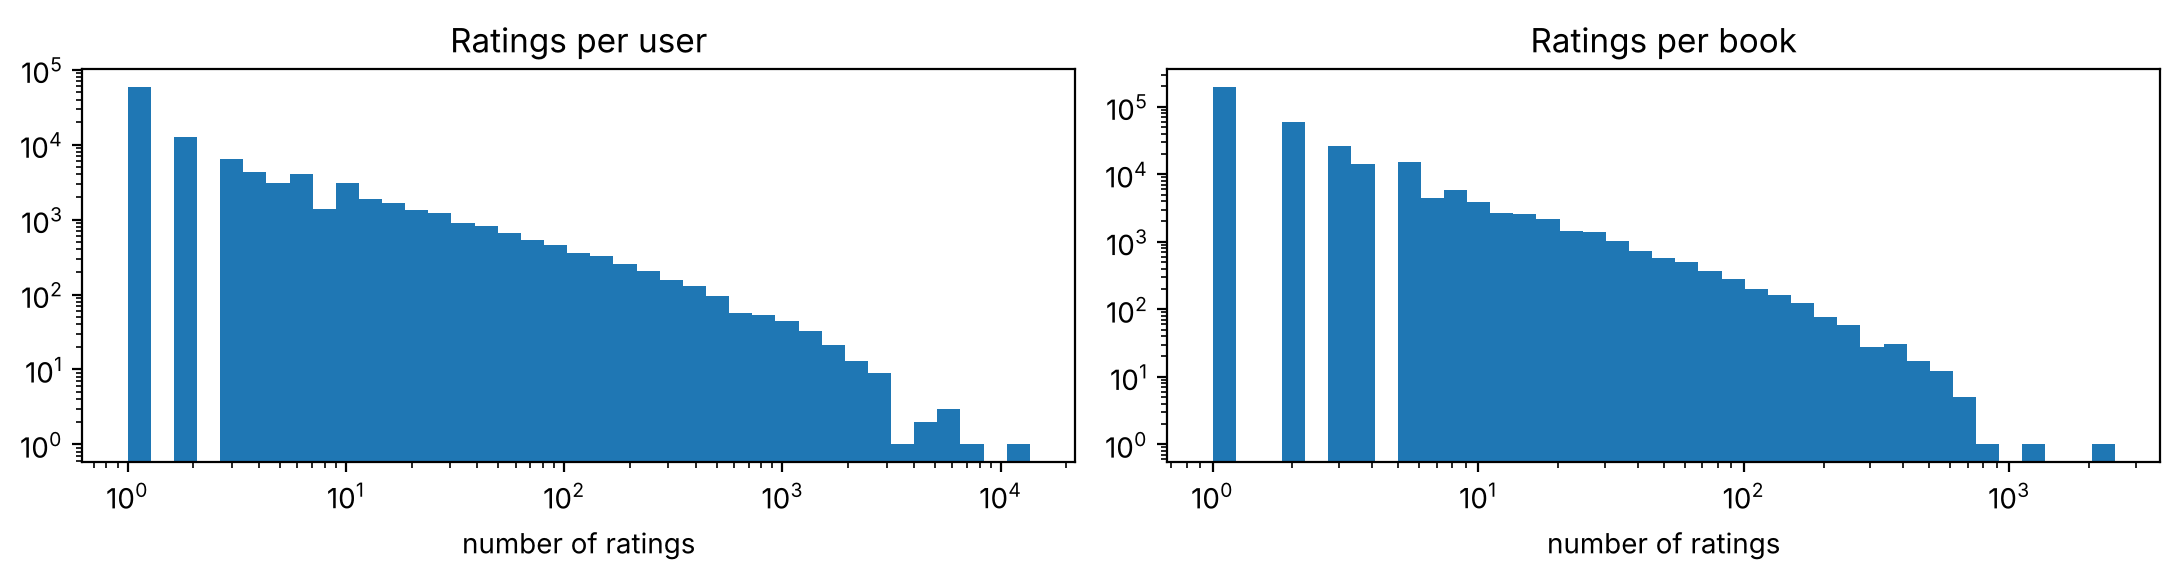

In [8]:
per_user = ratings_b.groupby("User-ID").size()
per_book = ratings_b.groupby("ISBN").size()

display(pd.DataFrame({"ratings per user": per_user.describe(), "ratings per book": per_book.describe()}))
for label, counts in (("users", per_user), ("books", per_book)):
    print(f"{label}: {(counts == 1).mean():.1%} have only 1 rating, {(counts < 10).mean():.1%} have fewer than 10")

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, counts, title in ((axes[0], per_user, "Ratings per user"), (axes[1], per_book, "Ratings per book")):
    ax.hist(counts, bins=np.logspace(0, np.log10(counts.max() + 1), 40))
    ax.set(xscale="log", yscale="log", title=title, xlabel="number of ratings")
plt.tight_layout()
plt.show()

**Finding:** 56.2% of users and 57.9% of books have only 1 rating (87.6% of users and 94.6% of books have fewer than 10), while one user has 13,602 → **Silver:** set a minimum number of ratings for both users and books.

### 2.5 Matrix sparsity

In [9]:
n_users = ratings_b["User-ID"].nunique()
n_books = ratings_b["ISBN"].nunique()
possible = n_users * n_books

for label, mask in (("all rows (including 0)", rating_values.notna()), ("explicit ratings only (1-10)", rating_values > 0)):
    filled = ratings_b[mask][["User-ID", "ISBN"]].drop_duplicates().shape[0]
    density = filled / possible
    print(f"{label}: {filled:,} of {possible:,} pairs are filled -> "
          f"{density:.5%} filled, sparsity = {1 - density:.5%}")

all rows (including 0): 1,149,780 of 35,854,757,348 pairs are filled -> 0.00321% filled, sparsity = 99.99679%
explicit ratings only (1-10): 433,671 of 35,854,757,348 pairs are filled -> 0.00121% filled, sparsity = 99.99879%


**Finding:** the matrix is 99.9968% empty with all rows and 99.9988% empty with real ratings only → **Silver/Gold:** remove rare users and books, and store the matrix in sparse form.

## Step 3: Clean the data and build the Silver layer

### 3.1 Users: duplicates, age and location

In [10]:
def fix_encoding(text):
    """Some names were saved as UTF-8 inside this latin-1 file, so one letter shows as two. Repair them."""
    def decode(raw, original):
        try:
            return raw.decode("utf-8")
        except UnicodeDecodeError:
            return original

    # damaged twice: "\u00c3?\u00c2\u00a9" -> "\u00e9"
    text = re.sub("\u00c3\\?\u00c2([\u0080-\u00bf])",
                  lambda m: decode(bytes([0xC3, ord(m[1])]), m[0]), text)
    # damaged once: "\u00c3\u00a9" -> "\u00e9"
    return re.sub("[\u00c2-\u00df][\u0080-\u00bf]|[\u00e0-\u00ef][\u0080-\u00bf]{2}",
                  lambda m: decode(m[0].encode("latin-1"), m[0]), text)


def clean_text(value):
    """Fix HTML codes and letters, remove extra spaces, and turn empty words into None."""
    text = fix_encoding(html.unescape(str(value)))
    text = re.sub(r"\s+", " ", text).strip()
    return None if text.lower() in MISSING_WORDS else text


def title_case(text):
    """Capital letter at the start of each word (keeps "Sorcerer's" correct)."""
    if not isinstance(text, str):     # missing value
        return None
    text = re.sub(r"(?<![\w'’])\w", lambda m: m.group().upper(), text.lower())
    # names like O'Brien and D'Este
    return re.sub(r"\b([OD]['’])(\w)(?=\w)", lambda m: m[1] + m[2].upper(), text)


def split_location(location):
    """'city, state, country' -> (city, state, country). The last part is the country."""
    parts = [clean_text(p.strip(' "')) for p in str(location).split(",")]
    if len(parts) >= 3:
        city = ", ".join(p for p in parts[:-2] if p) or None
        return city, parts[-2], parts[-1]
    if len(parts) == 2:
        return parts[0], None, parts[1]
    return parts[0], None, None


users = users_b.drop(columns="ingestion_timestamp").drop_duplicates()
users = users.rename(columns={"User-ID": "user_id", "Location": "location", "Age": "age"})
users["user_id"] = pd.to_numeric(users["user_id"].str.strip(), errors="coerce")
users = users.dropna(subset=["user_id"]).astype({"user_id": "int64"}).drop_duplicates("user_id")

users["age"] = pd.to_numeric(users["age"], errors="coerce")
users.loc[(users["age"] < 5) | (users["age"] > 100), "age"] = np.nan
median_age = users["age"].median()
users["age_was_filled"] = users["age"].isna()
users["age"] = users["age"].fillna(median_age)
print("Median age used for filling:", median_age)

location = pd.DataFrame(users["location"].map(split_location).tolist(),
                        columns=["city", "state", "country"], index=users.index)
for column in location:
    location[column] = location[column].map(title_case)
location["country"] = location["country"].replace({"Usa": "USA", "Uk": "UK"})
users = pd.concat([users.drop(columns="location"), location], axis=1)
users.head()

Median age used for filling: 32.0


,user_id,age,age_was_filled,city,state,country
0,1,32.0,True,Nyc,New York,USA
1,2,18.0,False,Stockton,California,USA
2,3,32.0,True,Moscow,Yukon Territory,Russia
3,4,17.0,False,Porto,V.N.Gaia,Portugal
4,5,32.0,True,Farnborough,Hants,United Kingdom


### 3.2 Books: duplicates, years, text and image columns

The same book often has many ISBNs (hardcover, paperback, new print).
So each unique **title + author** gets one `book_id`. This joins the ratings of all editions
and stops the recommender from suggesting another edition of a book the user already read.

In [11]:
books = books_b.drop(columns=["ingestion_timestamp", "Image-URL-S", "Image-URL-M", "Image-URL-L"], errors="ignore")
books = books.drop_duplicates().rename(columns={
    "ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
    "Year-Of-Publication": "year", "Publisher": "publisher",
})
books["isbn"] = books["isbn"].str.strip().str.upper()
books = books.drop_duplicates("isbn")

books["year"] = pd.to_numeric(books["year"], errors="coerce")
books.loc[(books["year"] <= 0) | (books["year"] > datetime.now().year), "year"] = np.nan
books["year"] = books["year"].astype("Int64")

for column in ("title", "author", "publisher"):
    books[column] = books[column].map(clean_text).map(title_case)
books = books.dropna(subset=["title"])
books["author"] = books["author"].fillna("Unknown")


def match_key(series):
    """Letters and digits only, so 'J. K. Rowling' and 'J.K. Rowling' match."""
    return series.map(lambda text: re.sub(r"[\W_]+", "", text.lower()))


title_key = match_key(books["title"])
title_key = title_key.where(title_key != "", books["title"].str.lower())
books["book_id"] = pd.factorize(title_key + "|" + match_key(books["author"]))[0]

print(f"{len(books):,} ISBNs -> {books['book_id'].nunique():,} unique books")
books.head()

271,064 ISBNs -> 245,305 unique books


,isbn,title,author,year,publisher,book_id
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,0
1,0002005018,Clara Callan,Richard Bruce Wright,2001,Harperflamingo Canada,1
2,0060973129,Decision In Normandy,Carlo D'Este,1991,Harperperennial,2
3,0374157065,Flu: The Story Of The Great Influenza Pandemic Of 1918 And The Search For Th...,Gina Bari Kolata,1999,Farrar Straus Giroux,3
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999,W. W. Norton & Company,4


### 3.3 Ratings: remove duplicates, zeros and unknown users or books

In [12]:
ratings = ratings_b.drop(columns="ingestion_timestamp").rename(
    columns={"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})
steps = [("bronze", len(ratings))]

ratings = ratings.drop_duplicates()
ratings["user_id"] = pd.to_numeric(ratings["user_id"].str.strip(), errors="coerce")
ratings["isbn"] = ratings["isbn"].str.strip().str.upper()
ratings["rating"] = pd.to_numeric(ratings["rating"], errors="coerce")
ratings = ratings.dropna().astype({"user_id": "int64"})
steps.append(("after removing exact duplicates and bad values", len(ratings)))

ratings = ratings[ratings["rating"].between(1, 10)]
steps.append(("after removing 0 ratings (keep 1-10)", len(ratings)))

ratings = ratings[ratings["user_id"].isin(users["user_id"])]
ratings = ratings.merge(books[["isbn", "book_id"]], on="isbn", how="inner")
steps.append(("after keeping only known users and books", len(ratings)))

# One row per user and book. If a user rated two editions, use the average.
ratings = ratings.groupby(["user_id", "book_id"], as_index=False)["rating"].mean()
steps.append(("after one rating per user per book", len(ratings)))

pd.DataFrame(steps, columns=["step", "rows"])

,step,rows
0,bronze,1149780
1,after removing exact duplicates and bad values,1149780
2,after removing 0 ratings (keep 1-10),433671
3,after keeping only known users and books,383853
4,after one rating per user per book,382873


### 3.4 Minimum number of ratings

When we remove rare books, some users drop below the limit (and the other way round).
So the filter is repeated until nothing changes. The table compares different limits.

In [13]:
def filter_min_ratings(table, minimum):
    while True:
        user_ok = table.groupby("user_id")["book_id"].transform("size") >= minimum
        book_ok = table.groupby("book_id")["user_id"].transform("size") >= minimum
        keep = user_ok & book_ok
        if keep.all():
            return table
        table = table[keep]


comparison = []
for minimum in (1, 3, 5, 10, 20):
    t = filter_min_ratings(ratings, minimum)
    u, b = t["user_id"].nunique(), t["book_id"].nunique()
    comparison.append({
        "minimum": minimum, "ratings": len(t), "users": u, "books": b,
        "sparsity %": round(100 * (1 - len(t) / (u * b)), 3) if u and b else None,
        "avg ratings per book": round(len(t) / b, 1) if b else None,
    })
pd.DataFrame(comparison)

,minimum,ratings,users,books,sparsity %,avg ratings per book
0,1,382873,68092,136608,99.996,2.8
1,3,196114,15189,21942,99.941,8.9
2,5,130854,7563,9352,99.815,14.0
3,10,55734,2257,2441,98.988,22.8
4,20,0,0,0,NaN,NaN


In [14]:
MIN_RATINGS = 5
ratings_silver = filter_min_ratings(ratings, MIN_RATINGS).reset_index(drop=True)
users_silver = users[users["user_id"].isin(ratings_silver["user_id"])].reset_index(drop=True)
books_silver = books[books["book_id"].isin(ratings_silver["book_id"])].reset_index(drop=True)

users_silver.to_parquet(SILVER / "users.parquet", index=False)
books_silver.to_parquet(SILVER / "books.parquet", index=False)
ratings_silver.to_parquet(SILVER / "ratings.parquet", index=False)

print(f"Threshold: at least {MIN_RATINGS} ratings per user and per book")
print("users:", users_silver.shape, "| books:", books_silver.shape, "| ratings:", ratings_silver.shape)

Threshold: at least 5 ratings per user and per book
users: (7563, 6) | books: (17869, 6) | ratings: (130854, 3)


**Chosen threshold: 5.** The EDA shows that most users and books have only 1 rating, and such books cannot give reliable similarity. A limit of 10 leaves only 2,257 users and 2,441 books. A limit of 5 keeps 7,563 users, 9,352 books (about 3.8 times more) and 130,854 ratings, with about 14 ratings per book. So 5 gives a good balance between quality and the number of books we can recommend.

In [15]:
# Quality checks on Silver
assert users_silver["user_id"].is_unique
assert books_silver["isbn"].is_unique
assert not ratings_silver.duplicated(["user_id", "book_id"]).any()
assert ratings_silver["rating"].between(1, 10).all()
assert users_silver["age"].between(5, 100).all()
assert books_silver["year"].dropna().between(1, datetime.now().year).all()
assert ratings_silver.groupby("user_id").size().min() >= MIN_RATINGS
assert ratings_silver.groupby("book_id").size().min() >= MIN_RATINGS
assert set(ratings_silver["user_id"]) <= set(users_silver["user_id"])
assert set(ratings_silver["book_id"]) <= set(books_silver["book_id"])
print("All Silver checks passed")

All Silver checks passed


## Step 4: Build the Gold layer

In [16]:
r = pd.read_parquet(SILVER / "ratings.parquet")
b = pd.read_parquet(SILVER / "books.parquet")

user_ids = np.sort(r["user_id"].unique())
book_ids = np.sort(r["book_id"].unique())
r["user_idx"] = np.searchsorted(user_ids, r["user_id"])   # row of the matrix
r["book_idx"] = np.searchsorted(book_ids, r["book_id"])   # column of the matrix

# 1) Sparse user-book rating matrix
user_book = sparse.csr_matrix(
    (r["rating"].astype("float32"), (r["user_idx"], r["book_idx"])),
    shape=(len(user_ids), len(book_ids)),
)
sparse.save_npz(GOLD / "user_book_matrix.npz", user_book)
pd.DataFrame({"user_idx": np.arange(len(user_ids)), "user_id": user_ids}).to_parquet(
    GOLD / "user_index.parquet", index=False)

# 2) Book lookup table. For each book, use the title and author of its most rated edition.
isbn_counts = ratings_b["ISBN"].str.strip().str.upper().value_counts()
book_lookup = (
    b.assign(popularity=b["isbn"].map(isbn_counts).fillna(0))
     .sort_values(["book_id", "popularity", "isbn"], ascending=[True, False, True])
     .drop_duplicates("book_id")[["book_id", "title", "author"]]
     .reset_index(drop=True)
)
book_lookup.insert(0, "book_idx", np.searchsorted(book_ids, book_lookup["book_id"]))
book_lookup.to_parquet(GOLD / "book_lookup.parquet", index=False)

# 3) Aggregates
user_stats = r.groupby("user_id")["rating"].agg(avg_rating="mean", num_ratings="size").reset_index()
book_stats = r.groupby("book_id")["rating"].agg(avg_rating="mean", num_ratings="size").reset_index()
user_stats.to_parquet(GOLD / "user_stats.parquet", index=False)
book_stats.to_parquet(GOLD / "book_stats.parquet", index=False)

density = user_book.nnz / (user_book.shape[0] * user_book.shape[1])
print(f"Matrix: {user_book.shape[0]:,} users x {user_book.shape[1]:,} books, "
      f"{user_book.nnz:,} ratings, sparsity {1 - density:.3%}")
display(book_stats.merge(book_lookup, on="book_id").nlargest(10, "num_ratings")
        [["title", "author", "num_ratings", "avg_rating"]])
display(user_stats.head())

Matrix: 7,563 users x 9,352 books, 130,854 ratings, sparsity 99.815%


,title,author,num_ratings,avg_rating
204,The Lovely Bones: A Novel,Alice Sebold,384,8.276042
351,The Da Vinci Code,Dan Brown,308,8.568182
180,The Secret Life Of Bees,Sue Monk Kidd,261,8.561303
1374,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,241,8.926694
85,Bridget Jones's Diary,Helen Fielding,237,7.696906
256,The Nanny Diaries: A Novel,Emma Mclaughlin,233,7.341202
202,Divine Secrets Of The Ya-Ya Sisterhood: A Novel,Rebecca Wells,231,7.932900
250,The Red Tent (Bestselling Backlist),Anita Diamant,222,8.414414
125,Life Of Pi,Yann Martel,218,8.201835
1515,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,212,9.106132


,user_id,avg_rating,num_ratings
0,99,7.200000,5
1,114,8.571429,7
2,243,7.411765,17
3,244,7.571429,7
4,254,8.151515,33


## Step 5: Build the recommender (item-based collaborative filtering)

Two books are similar when the same users give them similar ratings.
**Cosine similarity** compares the rating rows of two books: `1 - cosine distance`.

In [17]:
# 5.1 Load from Gold: rows = books, columns = users
user_book = sparse.load_npz(GOLD / "user_book_matrix.npz")
book_user = user_book.T.tocsr()
lookup = pd.read_parquet(GOLD / "book_lookup.parquet").set_index("book_idx").sort_index()
stats = pd.read_parquet(GOLD / "book_stats.parquet").set_index("book_id")
lookup["num_ratings"] = lookup["book_id"].map(stats["num_ratings"])
user_row = pd.read_parquet(GOLD / "user_index.parquet").set_index("user_id")["user_idx"]
print("book x user matrix:", book_user.shape)

# 5.2 Cosine similarity between books
knn = NearestNeighbors(metric="cosine", algorithm="brute")
knn.fit(book_user)


def neighbours(book_idx, k):
    """The k most similar books as (book_idx, similarity), without the book itself."""
    k_search = min(k + 1, book_user.shape[0])
    distance, index = knn.kneighbors(book_user[book_idx], n_neighbors=k_search)
    pairs = [(int(i), float(1 - d)) for d, i in zip(distance[0], index[0]) if i != book_idx]
    return [(i, s) for i, s in pairs if s > 1e-6][:k]   # similarity 0 means nothing in common

book x user matrix: (9352, 7563)


### 5.3 Similar books for a title

In [18]:
def find_book(title):
    """Exact title first, then partial match. If many match, take the most rated one."""
    names = lookup["title"].str.lower()
    wanted = title.strip().lower()
    matches = lookup[names == wanted]
    if matches.empty:
        matches = lookup[names.str.contains(wanted, regex=False)]
    if matches.empty:
        raise ValueError(f"No book found for title: {title!r}")
    return int(matches["num_ratings"].idxmax())


def similar_books(title, n=10):
    book_idx = find_book(title)
    print(f"Books similar to: {lookup.at[book_idx, 'title']} - {lookup.at[book_idx, 'author']}")
    rows = [{"title": lookup.at[i, "title"], "author": lookup.at[i, "author"], "similarity": round(s, 3)}
            for i, s in neighbours(book_idx, n)]
    return pd.DataFrame(rows, index=range(1, len(rows) + 1))

In [19]:
most_rated = lookup.nlargest(3, "num_ratings")["title"].tolist()
for name in most_rated:
    display(similar_books(name))

Books similar to: The Lovely Bones: A Novel - Alice Sebold


,title,author,similarity
1,Where The Heart Is (Oprah's Book Club (Paperback)),Billie Letts,0.153
2,Lucky : A Memoir,Alice Sebold,0.151
3,The Da Vinci Code,Dan Brown,0.132
4,Life Of Pi,Yann Martel,0.130
5,The Secret Life Of Bees,Sue Monk Kidd,0.129
6,Lucky,Alice Sebold,0.128
7,Good In Bed,Jennifer Weiner,0.125
8,The Pact: A Love Story,Jodi Picoult,0.122
9,Suzanne's Diary For Nicholas,James Patterson,0.120
10,The Book Of Ruth (Oprah's Book Club (Paperback)),Jane Hamilton,0.117


Books similar to: The Da Vinci Code - Dan Brown


,title,author,similarity
1,Angels & Demons,Dan Brown,0.226
2,Middlesex: A Novel,Jeffrey Eugenides,0.139
3,Digital Fortress : A Thriller,Dan Brown,0.138
4,The Lovely Bones: A Novel,Alice Sebold,0.132
5,The Secret Life Of Bees,Sue Monk Kidd,0.127
6,The Twentieth Wife: A Novel,Indu Sundaresan,0.120
7,Sleep Tight (Onyx Book),Anne Frasier,0.115
8,The Cat Who Talked Turkey,Lilian Jackson Braun,0.112
9,The Narrows: A Novel,Michael Connelly,0.107
10,Stone Cold: A Jesse Stone Novel,Robert B. Parker,0.104


Books similar to: The Secret Life Of Bees - Sue Monk Kidd


,title,author,similarity
1,Three Junes,Julia Glass,0.150
2,The Five People You Meet In Heaven,Mitch Albom,0.143
3,Girl With A Pearl Earring,Tracy Chevalier,0.141
4,Good In Bed,Jennifer Weiner,0.141
5,Tears Of The Giraffe (No.1 Ladies Detective Agency),Alexander Mccall Smith,0.130
6,The Lovely Bones: A Novel,Alice Sebold,0.129
7,The Da Vinci Code,Dan Brown,0.127
8,Blue Shoe,Anne Lamott,0.126
9,The Rapture Of Canaan,Sheri Reynolds,0.122
10,Blue Diary,Alice Hoffman,0.121


### 5.4 Recommendations for a user

1. Take the books the user rated highly (8 or more). If there are none, take the user's best ratings.
2. For each of these books, collect the most similar books.
3. Score = sum of (similarity x user's rating).
4. Remove books the user has already read and return the top `n`.

In [20]:
HIGH_RATING = 8
NEIGHBOURS_PER_BOOK = 50


def user_history(user_id):
    """All books rated by the user, best first."""
    if user_id not in user_row.index:
        raise ValueError(f"User {user_id} is not in the Gold data (unknown or too few ratings).")
    row = user_book[user_row[user_id]]
    history = pd.DataFrame({"book_idx": row.indices, "rating": row.data})
    return history.sort_values(["rating", "book_idx"], ascending=[False, True])


def liked_books(user_id):
    history = user_history(user_id)
    liked = history[history["rating"] >= HIGH_RATING]
    return liked if not liked.empty else history[history["rating"] == history["rating"].max()]


def recommend(user_id, n=10):
    already_read = set(user_history(user_id)["book_idx"])
    scores, best_reason = {}, {}
    for book_idx, rating in liked_books(user_id).itertuples(index=False):
        for other, similarity in neighbours(int(book_idx), NEIGHBOURS_PER_BOOK):
            if other in already_read:
                continue
            weight = similarity * float(rating)
            scores[other] = scores.get(other, 0.0) + weight
            if weight > best_reason.get(other, (0.0, None))[0]:
                best_reason[other] = (weight, int(book_idx))
    top = sorted(scores, key=lambda i: (-scores[i], i))[:n]
    return pd.DataFrame(
        [{"title": lookup.at[i, "title"], "author": lookup.at[i, "author"], "score": round(scores[i], 3),
          "because you liked": lookup.at[best_reason[i][1], "title"]} for i in top],
        index=range(1, len(top) + 1),
    )

## Step 6: Demo and sanity check

In [21]:
# Pick users with a readable history (8 to 30 liked books), spread across the list
liked_count = pd.Series(np.asarray((user_book >= HIGH_RATING).sum(axis=1)).ravel(), index=user_row.index)
candidates = liked_count[liked_count.between(8, 30)].sort_index()
if len(candidates) < 3:
    candidates = liked_count.nlargest(3)
demo_users = [int(candidates.index[int(p * (len(candidates) - 1))]) for p in (0.1, 0.5, 0.9)]
demo_users

[30495, 141601, 249989]

In [22]:
for user_id in demo_users:
    liked = liked_books(user_id)
    recs = recommend(user_id, n=10)

    print(f"\n{'=' * 30} User {user_id} {'=' * 30}")
    print(f"Books rated highly: {len(liked)} (top 10 shown, next to the recommendations)")
    top_liked = liked.head(10)
    left = pd.DataFrame({
        "rated highly by user": [f"{lookup.at[i, 'title']} - {lookup.at[i, 'author']}" for i in top_liked["book_idx"]],
        "rating": top_liked["rating"].round(1).values,
    })
    right = pd.DataFrame({
        "recommended for user": list(recs["title"] + " - " + recs["author"]) if len(recs) else [],
        "score": list(recs["score"]) if len(recs) else [],
    })
    side_by_side = pd.concat([left, right], axis=1).astype(object).fillna("")
    side_by_side.index += 1
    display(side_by_side)

    # Sanity checks: no repeats and nothing already read
    read_titles = set(lookup.loc[user_history(user_id)["book_idx"], "title"] + "|" +
                      lookup.loc[user_history(user_id)["book_idx"], "author"])
    rec_titles = list(recs["title"] + "|" + recs["author"]) if len(recs) else []
    assert len(rec_titles) == len(set(rec_titles))
    assert not read_titles & set(rec_titles)
    print("Check passed: no repeated books and no already-read books.")


============================== User 30495 ==============================
Books rated highly: 12 (top 10 shown, next to the recommendations)


,rated highly by user,rating,recommended for user,score
1,Dragonsong (Harper Hall Trilogy) - Anne Mccaffrey,10.0,"Princess In The Spotlight (The Princess Diaries, Vol. 2) - Meg Cabot",7.288
2,Ender's Game (Ender Wiggins Saga (Paperback)) - Orson Scott Card,10.0,Dragondrums (Harper Hall Trilogy) - Anne Mccaffrey,7.139
3,Neverwhere - Neil Gaiman,10.0,Violet & Claire - Francesca Lia Block,6.605
4,The Princess Diaries - Meg Cabot,10.0,Fallen Angels - Larry Niven,6.428
5,Dragonsinger (Harper Hall Trilogy) - Anne Mccaffrey,10.0,Dangerous Angels: The Weetzie Bat Books - Francesca Lia Block,5.808
6,Crocodile On The Sandbank - Elizabeth Peters,10.0,You Know You Love Me: A Gossip Girl Novel - Cecily Von Ziegesar,5.764
7,"Angus, Thongs And Full-Frontal Snogging: Confessions Of Georgia Nicolson - L...",10.0,Echo - Francesca Lia Block,5.75
8,The Transall Saga - Gary Paulsen,9.0,"Princess In Love (The Princess Diaries, Vol. 3) - Meg Cabot",5.251
9,Acorna: The Unicorn Girl (Acorna (Paperback)) - Anne Mccaffrey,9.0,City Of Sorcery - Marion Zimmer Bradley,5.073
10,Sick Of Shadows - Sharyn Mccrumb,9.0,"Mary Anne Saves The Day (Baby-Sitters Club, 4) - Ann M. Martin",4.553


Check passed: no repeated books and no already-read books.



============================== User 141601 ==============================
Books rated highly: 9 (top 10 shown, next to the recommendations)


,rated highly by user,rating,recommended for user,score
1,Hygiene De Lassassin - Amelie Nothomb,9.0,Metaphysique Des Tubes - Amelie Nothomb,12.579
2,Balzac Et La Petite Tailleuse Chino - Daj Sijie,9.0,Le Parfum : Histoire D'Un Meurtrier - Patrick Süskind,9.785
3,"Le Cycle D'Ender, Tome 2 : La Voix Des Morts - Scott Card Orson",9.0,"Le Combat Ordinaire, Tome 1 - Larcenet",9.617
4,"Le Cycle D'Ender, Tome 1 : La Stratégie Ender - Scott Card Orson",9.0,Haute Fidélité - Nick Hornby,9.585
5,Je Voudrais Que Quelqu'un M'attende Quelque Part - Anna Gavalda,8.0,Le Livre Du Voyage - Bernard Werber,9.575
6,Et Si C'etait Vrai / If This Were Only True - Marc Levy,8.0,Le Nom De La Rose - Umberto Eco,9.52
7,Stupeur Et Tremblements - Amelie Nothomb,8.0,Le Zebre - A. Jardin,9.447
8,Debout Les Morts - Fred Vargas,8.0,Le Petit Prince - Antoine De Saint-Exupéry,8.754
9,La Premiere Gorgee De Biere Et Autres Plaisirs Minuscules (L'arpenteur) - Ph...,8.0,God-Shaped Hole - Tiffanie Debartolo,8.015
10,,,Therese Desqueyroux - Francois Mauriac,7.732


Check passed: no repeated books and no already-read books.



============================== User 249989 ==============================
Books rated highly: 8 (top 10 shown, next to the recommendations)


,rated highly by user,rating,recommended for user,score
1,Angels & Demons - Dan Brown,10.0,Ashworth Hall (Charlotte & Thomas Pitt Novels (Paperback)) - Anne Perry,3.38
2,Where The Heart Is (Oprah's Book Club (Paperback)) - Billie Letts,8.0,"The Vampire Lestat (Vampire Chronicles, Book Ii) - Anne Rice",2.932
3,"Blackwood Farm (Rice, Anne, Vampire Chronicles.) - Anne Rice",8.0,The Hyde Park Headsman - Anne Perry,2.892
4,Interview With The Vampire - Anne Rice,8.0,The Tale Of The Body Thief (Vampire Chronicles (Paperback)) - Anne Rice,2.551
5,Bloodstream - Tess Gerritsen,8.0,The Da Vinci Code - Dan Brown,2.255
6,Brunswick Gardens (Charlotte & Thomas Pitt Novels (Paperback)) - Anne Perry,8.0,Traitor's Gate - Anne Perry,2.237
7,The Summons - John Grisham,8.0,Digital Fortress : A Thriller - Dan Brown,2.179
8,"Mary, Called Magdalene - Margaret George",8.0,Stephen Coonts' Deep Black (Deep Black) - Stephen Coonts,2.152
9,,,Generous Death - Nancy Pickard,2.125
10,,,Shadows Of Steel - Dale Brown,2.106


Check passed: no repeated books and no already-read books.


**What the demo shows:**

- User 30495 likes young-adult and fantasy books and gets next books of the same series (Princess Diaries, Harper Hall) and similar authors.
- User 141601 reads French books and gets mostly French books, including another book by Amelie Nothomb.
- User 249989 gets more books by Anne Perry, Anne Rice and Dan Brown, who are already in the liked list.

**Limits:** the matrix is still 99.8% empty, so similarity values are small. The method cannot help users or books that were removed by the threshold. The same book written with a different title can still appear as a separate book.